# Philippine inflation forecasting - simple proposal experiment
**DATA CLEANING -> DATA PREPARATION -> MODELING -> RESULTS**

Predict Philippine national headline inflation one, two and three months ahead using historical inflation and the proposal's core indicators: PHP/USD exchange rate, BSP policy rate and M3 money supply.

The code is written directly in this notebook. There are no local `src` imports and no web app/database steps. Earlier experiments stay unchanged. Use the project's `.venv` kernel and run from top to bottom.

This notebook follows the example's short, numbered sections and explanations. It uses the proposal's forecasting methods, not the unrelated classification/clustering algorithms in the example.

## A. DATA CLEANING
### A1. Import the libraries and locate the files
`pandas` reads tables, `numpy` handles numbers, `matplotlib` draws plots, and `SARIMAX` fits both SARIMA and SARIMAX. `re` extracts rates from policy text.

In [1]:
from pathlib import Path
from datetime import datetime
import calendar
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox

ROOT = Path.cwd() if (Path.cwd() / "data/raw").exists() else Path.cwd().parent
RAW = ROOT / "data/raw"
OUT = ROOT / "artifacts/proposal_simple_experiment"
OUT.mkdir(parents=True, exist_ok=True)
get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.figsize": (11, 4), "figure.dpi": 110,
                     "axes.grid": True, "grid.alpha": 0.2})

### A2. Inspect the raw data
Look at the original headings and rows before cleaning. The inflation files store months in columns. The spreadsheets contain headings and blank cells that are not observations.

In [2]:
sample = pd.read_csv(RAW / "Dataset-12019-2026.csv", sep=";", skiprows=2, na_values=[".."])
display(sample.iloc[:, :8].head())
exchange_sheet = pd.read_excel(RAW / "pesodollar.xlsx", sheet_name="monthly", header=None)
policy_sheet = pd.read_excel(RAW / "MonetaryPolicyDecisions.xlsx", header=None)
money_sheet = pd.read_excel(RAW / "dcs_srf.xlsx", header=None)
display(exchange_sheet.iloc[:12, :5], policy_sheet.head(5), money_sheet.iloc[:6, :14])

,Geolocation,Commodity Description,2019 Jan,2019 Feb,2019 Mar,2019 Apr,2019 May,2019 Jun
0,PHILIPPINES,0 - ALL ITEMS,4.4,3.8,3.4,3.2,3.2,2.7


,0,1,2,3,4
0,Philippine Peso per US Dollar Rate,NaN,NaN,NaN,NaN
1,for periods indicated,NaN,NaN,NaN,NaN
2,,NaN,,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN
4,NaN,Period,NaN,Average,End-of-Period
5,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN
7,NaN,1945,January,2,n.a.
8,NaN,NaN,February,2,n.a.
9,NaN,NaN,March,2,n.a.


,0,1
0,MonetaryPolicyDecisions,NaN
1,Date,Description
2,2026-08-27,The Monetary Board decided to raise the BSP’s ...
3,2026-06-18,The Monetary Board decided to raise the BSP’s ...
4,2026-04-23,The Monetary Board decided to raise the BSP’s ...


,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Depository Corporations Survey1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,levels in million Philippine pesos,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,as of periods indicated,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2001-12-01 00:00:00,2002-01-01 00:00:00,2002-02-01 00:00:00,2002-03-01 00:00:00,2002-04-01 00:00:00
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### A3. Clean national headline inflation
Keep the Philippines all-items row. Convert month headings to dates and values to numbers. `..` means missing, not zero. Both supplied CSVs state the same 2018=100 basis. Inflation is already a year-on-year percent, so do not calculate another percent change.

In [3]:
parts = []
for filename in ["Dataset-11995-2018.csv", "Dataset-12019-2026.csv"]:
    table = pd.read_csv(RAW / filename, sep=";", skiprows=2, na_values=[".."])
    row = table[(table["Geolocation"] == "PHILIPPINES") &
                (table["Commodity Description"] == "0 - ALL ITEMS")]
    assert len(row) == 1, "Expected one national all-items row"
    values = row.iloc[0, 2:]
    values.index = pd.to_datetime(values.index, format="%Y %b")
    parts.append(pd.to_numeric(values, errors="raise"))

inflation = pd.concat(parts).sort_index().rename("inflation")
assert inflation.index.is_unique, "Review duplicate inflation months"
display(inflation.to_frame().tail(8))

,inflation
2026-05-01,6.8
2026-06-01,6.4
2026-07-01,6.2
2026-08-01,6.1
2026-09-01,NaN
2026-10-01,NaN
2026-11-01,NaN
2026-12-01,NaN


### A4. Clean the monthly average exchange rate
Use the `Average` column in the `monthly` sheet. Fill only the repeated year labels; do not invent missing exchange-rate values. Remove headings and other rows that have no valid month and numeric rate.

In [4]:
exchange = exchange_sheet.iloc[:, [1, 2, 3]].copy()
exchange.columns = ["year", "month", "exchange_rate"]
exchange["year"] = pd.to_numeric(exchange["year"], errors="coerce").ffill()
month_numbers = {name: number for number, name in enumerate(calendar.month_name) if name}
exchange["month"] = exchange["month"].astype(str).str.strip().map(month_numbers)
exchange["exchange_rate"] = pd.to_numeric(exchange["exchange_rate"], errors="coerce")
exchange = exchange.dropna(subset=["year", "month", "exchange_rate"])
exchange["date"] = pd.to_datetime(dict(year=exchange["year"].astype(int),
                                     month=exchange["month"].astype(int), day=1))
exchange = exchange.set_index("date")["exchange_rate"].sort_index()
assert exchange.index.is_unique
display(exchange.to_frame().tail())

,exchange_rate
date,
2026-04-01,60.291316
2026-05-01,61.441000
2026-06-01,61.251286
2026-07-01,61.596261
2026-08-01,61.328105


### A5. Clean M3 money supply
The supplied DCS sheet has date labels in Excel row 5 and **M3 levels** in row 25. Pandas uses positions 4 and 24 because it starts counting at zero. Do not use the M4 or M3/GDP rows. Labels such as `Jul-26 p` include a provisional marker; keep the month part for joining dates. Raw files are unchanged.

In [5]:
assert "M3 (M2" in str(money_sheet.iloc[24, 2]), "Check the M3 source row"
money_rows = []
for label, value in zip(money_sheet.iloc[4], money_sheet.iloc[24]):
    number = pd.to_numeric(value, errors="coerce")
    if pd.isna(number):
        continue
    if isinstance(label, (pd.Timestamp, datetime)):
        date = pd.Timestamp(label)
    elif isinstance(label, str) and re.match(r"^[A-Za-z]{3}-\d{2}", label):
        date = pd.to_datetime(label[:6], format="%b-%y")
    else:
        continue
    money_rows.append({"date": date, "m3": number})

money = pd.DataFrame(money_rows).set_index("date")["m3"].sort_index()
assert money.index.is_unique
display(money.to_frame().tail())

,m3
date,
2026-03-01,2.038250e+07
2026-04-01,2.034729e+07
2026-05-01,2.060313e+07
2026-06-01,2.053946e+07
2026-07-01,2.051968e+07


### A6. Clean the BSP policy-rate decisions
The file contains decision text, not a ready monthly table. Read the first rate stated before `percent`, after `at` or `to`; this avoids later deposit/lending rates. Keep descriptions without a numeric match for review. Use the last decision in each month and carry the last known rate forward when there is no new numeric decision.

This simple text rule needs manual checking, especially exact effective dates and the 2016 policy-framework change. It is not a complete policy-history audit.

In [6]:
policy_rows = []
policy_review = []
for date_text, description in policy_sheet.iloc[:, :2].itertuples(index=False, name=None):
    if not re.match(r"^\d{4}-\d{2}-\d{2}", str(date_text)):
        continue
    first_rate_text = str(description).split("percent")[0]
    match = re.search(r"(?:at|to)\s+(\d+(?:\.\d+)?)\s*$", first_rate_text)
    if match:
        policy_rows.append({"date": pd.Timestamp(date_text), "policy_rate": float(match.group(1))})
    else:
        policy_review.append({"date": date_text, "description": description})

policy = pd.DataFrame(policy_rows).sort_values("date").set_index("date")
policy.index = policy.index.to_period("M").to_timestamp()
policy = policy.groupby(level=0).last()
policy = policy.reindex(pd.date_range("2010-01-01", "2026-07-01", freq="MS")).ffill()
policy = policy["policy_rate"]
display(pd.DataFrame(policy_review), policy.to_frame().tail())
pd.DataFrame(policy_review).to_csv(OUT / "policy_review.csv", index=False)

,date,description
0,2011-12-01,The Monetary Board decided to maintain the ove...
1,2011-10-20,The Monetary Board decided to maintain the ove...
2,2011-09-08,The Monetary Board decided to keep the overnig...
3,2011-07-28,The Monetary Board decided to maintain the BSP...
4,2011-06-16,The Monetary Board decided to keep policy rate...


,policy_rate
2026-03-01,4.25
2026-04-01,4.50
2026-05-01,4.50
2026-06-01,4.75
2026-07-01,4.75


## B. DATA PREPARATION
### B1. Join the four monthly series and check them
Use January 2010–July 2026: 199 months, matching the proposal's intended primary period. Keep one national row per month. Check missing values and duplicate dates; stop for review rather than fill inflation/M3 or delete real inflation spikes. `ms.xls` ends before this period, so it is not needed. Unemployment was not supplied and is not added artificially.

In [7]:
data = pd.concat([inflation, exchange, policy, money], axis=1).sort_index()
data = data.loc["2010-01-01":"2026-07-01"].asfreq("MS")
data.index.name = "date"
display(data.head(), data.tail())
display(data.isna().sum().rename("missing values").to_frame())
print("Rows:", len(data), "| Duplicate dates:", data.index.duplicated().sum())
assert len(data) == 199 and data.index.is_unique
assert data.notna().all().all(), "Review missing source data"
assert data.index.equals(pd.date_range("2010-01-01", "2026-07-01", freq="MS", name="date"))
assert data[["exchange_rate", "m3"]].gt(0).all().all()
print("Passed: 199 continuous months; all four source series are present.")

C:\Users\Luzan\AppData\Local\Temp\ipykernel_24868\1704758699.py:1: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  data = pd.concat([inflation, exchange, policy, money], axis=1).sort_index()


,inflation,exchange_rate,policy_rate,m3
date,,,,
2010-01-01,3.9,46.027600,4.0,3.910182e+06
2010-02-01,3.9,46.311600,4.0,3.939374e+06
2010-03-01,3.9,45.742478,4.0,3.991470e+06
2010-04-01,4.0,44.626579,4.0,4.025107e+06
2010-05-01,3.9,45.597105,4.0,4.046092e+06


,inflation,exchange_rate,policy_rate,m3
date,,,,
2026-03-01,4.1,59.406905,4.25,2.038250e+07
2026-04-01,7.2,60.291316,4.50,2.034729e+07
2026-05-01,6.8,61.441000,4.50,2.060313e+07
2026-06-01,6.4,61.251286,4.75,2.053946e+07
2026-07-01,6.2,61.596261,4.75,2.051968e+07


,missing values
inflation,0
exchange_rate,0
policy_rate,0
m3,0


Rows: 199 | Duplicate dates: 0
Passed: 199 continuous months; all four source series are present.


### B2. Prepare M3 growth and older indicator values
M3 is in million pesos. Convert it to annual growth: `100 × (this month / same month last year − 1)`.

For each target month, use indicators from **five months earlier**. At a three-month horizon this is two months before the origin, so actual future indicators are not supplied. This is a stated reporting-delay assumption; original release dates and older data versions were not supplied.

The first twelve rows cannot have M3 growth; lagging loses five more. Remove only this expected starting gap. All models use the same remaining 182 months.

In [8]:
data["m3_growth"] = data["m3"].pct_change(12, fill_method=None) * 100
inputs = ["exchange_rate", "policy_rate", "m3_growth"]
lag_columns = ["exchange_lag5", "policy_lag5", "m3_growth_lag5"]
data[lag_columns] = data[inputs].shift(5)
model_data = data.dropna(subset=["inflation"] + lag_columns).copy()
assert len(model_data) == 182
assert model_data.index[0] == pd.Timestamp("2011-06-01")
display(model_data[["inflation"] + lag_columns].head())
data.to_csv(OUT / "prepared_data.csv")

,inflation,exchange_lag5,policy_lag5,m3_growth_lag5
date,,,,
2011-06-01,5.2,44.172190,4.00,8.884225
2011-07-01,4.9,43.703100,4.00,9.252224
2011-08-01,4.6,43.516000,4.25,9.865730
2011-09-01,4.7,43.240158,4.25,6.635111
2011-10-01,5.2,43.130727,4.50,7.774955


### B3. Plot the prepared series
Each variable has its own units. These plots describe history; they do not show cause and effect.

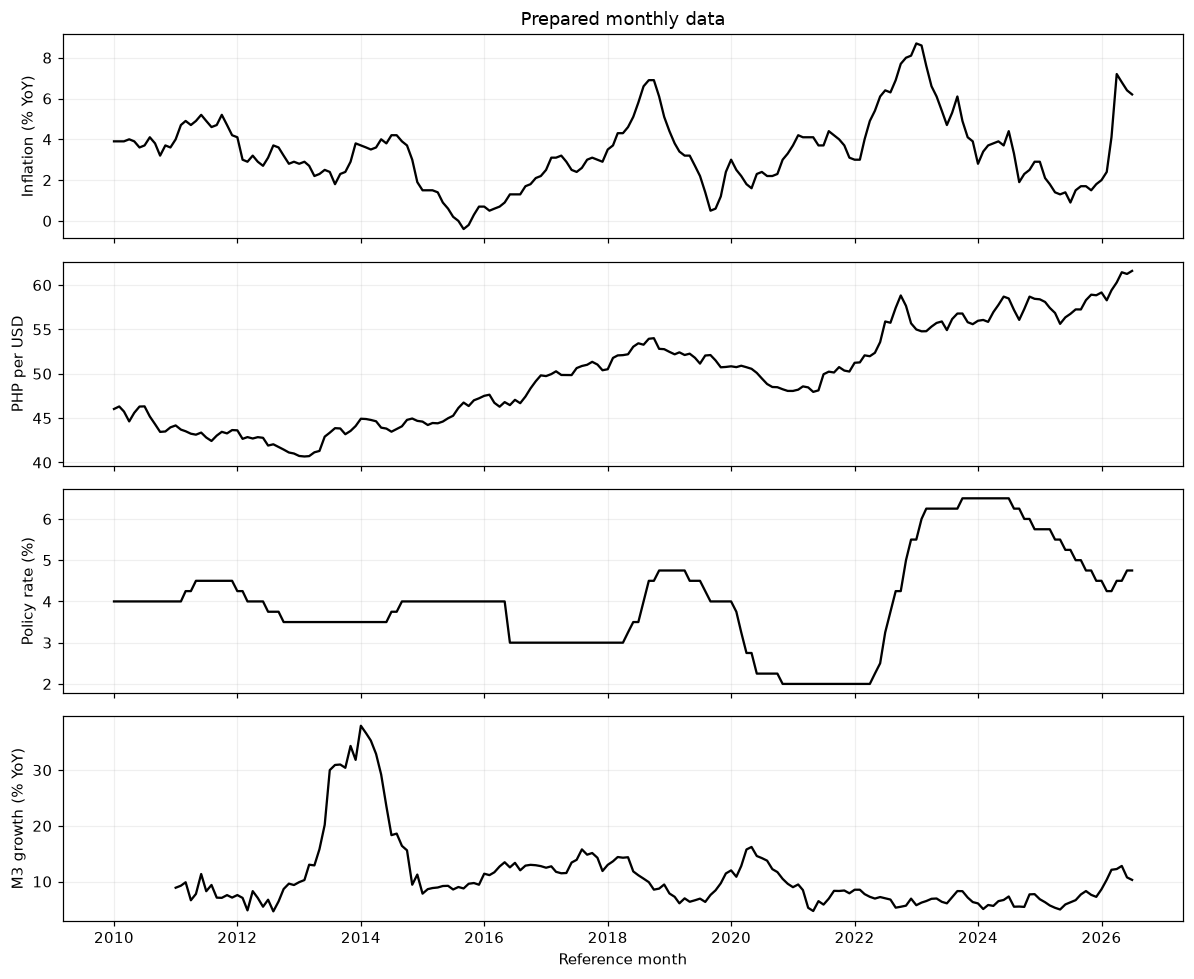

In [9]:
fig, axes = plt.subplots(4, 1, figsize=(11, 9), sharex=True)
for axis, column, unit in zip(axes, ["inflation"] + inputs,
                            ["Inflation (% YoY)", "PHP per USD", "Policy rate (%)", "M3 growth (% YoY)"]):
    axis.plot(data.index, data[column], color="black")
    axis.set_ylabel(unit)
axes[0].set_title("Prepared monthly data")
axes[-1].set_xlabel("Reference month")
fig.tight_layout()
fig.savefig(OUT / "01_prepared_data.png")
plt.show()
plt.close(fig)

### B4. Keep dates in order
Use twelve validation target months before the final twenty-four target months. Choose a model using validation errors only. Report the final block afterwards without changing that choice. No random train/test split.

These historical months were already seen in earlier experiments. They are **not a fresh untouched test**. This is a simpler, proposal-aligned comparison on the same supplied files, not new independent proof.

In [10]:
validation_months = model_data.index[-36:-24]
test_months = model_data.index[-24:]
display(pd.DataFrame({
    "block": ["Validation", "Previously seen final test"],
    "first target": [validation_months[0], test_months[0]],
    "last target": [validation_months[-1], test_months[-1]],
    "months per horizon": [len(validation_months), len(test_months)]
}))

,block,first target,last target,months per horizon
0,Validation,2023-08-01,2024-07-01,12
1,Previously seen final test,2024-08-01,2026-07-01,24


## C. MODELING
### C1. Define the comparisons
**Naive:** repeat the latest inflation value. **Seasonal naive:** use the same month last year.
**SARIMA:** use inflation history. **SARIMAX:** add older economic indicators.

Test each indicator separately, then all three together, as the proposal requires. This is a small fixed comparison, not a large search for the best settings. Order `(1,0,0)` uses one past-value term, no differencing and no error term. Seasonal `(1,0,0,12)` uses a twelve-month seasonal term. The model includes an intercept.

For SARIMAX, subtract each training-column mean and divide by its training standard deviation so the units have comparable scales. Apply those same training numbers to future inputs. Do not use future data when calculating them.

In [11]:
models = {
    "Naive": [],
    "Seasonal naive": [],
    "SARIMA": [],
    "SARIMAX exchange": ["exchange_lag5"],
    "SARIMAX policy": ["policy_lag5"],
    "SARIMAX M3": ["m3_growth_lag5"],
    "SARIMAX combined": lag_columns
}
display(pd.DataFrame({"model": list(models), "older indicators used": list(models.values())}))

def make_forecast(name, train, future_x):
    dates = future_x.index
    if name == "Naive":
        return np.repeat(train["inflation"].iloc[-1], len(dates)), None
    if name == "Seasonal naive":
        values = [train.loc[date - pd.DateOffset(years=1), "inflation"] for date in dates]
        return np.array(values), None

    columns = models[name]
    train_x = future_inputs = None
    if columns:
        mean = train[columns].mean()
        deviation = train[columns].std().replace(0, 1)
        train_x = (train[columns] - mean) / deviation
        future_inputs = (future_x[columns] - mean) / deviation

    model = SARIMAX(train["inflation"], exog=train_x, order=(1, 0, 0),
                    seasonal_order=(1, 0, 0, 12), trend="c",
                    enforce_stationarity=False, enforce_invertibility=False)
    fitted = model.fit(disp=False, maxiter=300)
    prediction = fitted.get_forecast(steps=len(dates), exog=future_inputs)
    return np.asarray(prediction.predicted_mean), fitted

,model,older indicators used
0,Naive,[]
1,Seasonal naive,[]
2,SARIMA,[]
3,SARIMAX exchange,[exchange_lag5]
4,SARIMAX policy,[policy_lag5]
5,SARIMAX M3,[m3_growth_lag5]
6,SARIMAX combined,"[exchange_lag5, policy_lag5, m3_growth_lag5]"


### C2. Fit using only information through each origin
For a target and horizon, the **origin** is the target minus that many months. Each fit uses inflation only through its origin. The same origin can serve several targets, so save its three predictions and reuse them rather than fit the same model again.

Record whether the numerical fit converged. Failed calculations stop execution; they are not replaced with another model's predictions. A nonconverged model is not eligible for selection.

In [12]:
records = []
for phase, targets in [("Validation", validation_months), ("Test", test_months)]:
    for name in models:
        saved_forecasts = {}
        for target in targets:
            for horizon in [1, 2, 3]:
                origin = target - pd.DateOffset(months=horizon)
                if origin not in saved_forecasts:
                    train = model_data.loc[:origin]
                    dates = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=3, freq="MS")
                    source_dates = dates - pd.DateOffset(months=5)
                    assert (source_dates <= origin - pd.DateOffset(months=2)).all()
                    future_x = pd.DataFrame(data.loc[source_dates, inputs].to_numpy(),
                                            index=dates, columns=lag_columns)
                    predicted, fitted = make_forecast(name, train, future_x)
                    converged = fitted is None or bool(fitted.mle_retvals["converged"])
                    saved_forecasts[origin] = (predicted, converged)
                predicted, converged = saved_forecasts[origin]
                actual = model_data.loc[target, "inflation"]
                records.append({"phase": phase, "model": name, "origin": origin,
                                "target": target, "horizon": horizon, "actual": actual,
                                "predicted": predicted[horizon - 1], "converged": converged})
        print(phase, name, "complete")

results = pd.DataFrame(records)
results["error"] = results["predicted"] - results["actual"]
assert np.isfinite(results[["predicted", "actual", "error"]]).all().all()
for phase, count in [("Validation", 12), ("Test", 24)]:
    rows = results[results["phase"] == phase]
    assert rows.groupby(["model", "horizon"]).size().eq(count).all()
    date_sets = rows.groupby(["model", "horizon"])["target"].apply(lambda dates: tuple(sorted(dates)))
    assert len(set(date_sets)) == 1, "Models must use the same target months"
display(results.head(9).round(4))

Validation Naive complete
Validation Seasonal naive complete


Validation SARIMA complete


Validation SARIMAX exchange complete


Validation SARIMAX policy complete


Validation SARIMAX M3 complete


Validation SARIMAX combined complete
Test Naive complete
Test Seasonal naive complete


... (6 outputs left out)

C:\Users\Luzan\Documents\Elec 4\.venv\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


Test SARIMAX combined complete


C:\Users\Luzan\AppData\Local\Temp\ipykernel_24868\3867934001.py:33: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(results.head(9).round(4))


,phase,model,origin,target,horizon,actual,predicted,converged,error
0,Validation,Naive,2023-07-01,2023-08-01,1,5.3,4.7,True,-0.6
1,Validation,Naive,2023-06-01,2023-08-01,2,5.3,5.4,True,0.1
2,Validation,Naive,2023-05-01,2023-08-01,3,5.3,6.1,True,0.8
3,Validation,Naive,2023-08-01,2023-09-01,1,6.1,5.3,True,-0.8
4,Validation,Naive,2023-07-01,2023-09-01,2,6.1,4.7,True,-1.4
5,Validation,Naive,2023-06-01,2023-09-01,3,6.1,5.4,True,-0.7
6,Validation,Naive,2023-09-01,2023-10-01,1,4.9,6.1,True,1.2
7,Validation,Naive,2023-08-01,2023-10-01,2,4.9,5.3,True,0.4
8,Validation,Naive,2023-07-01,2023-10-01,3,4.9,4.7,True,-0.2


## D. RESULTS
### D1. Calculate errors and choose on validation only
**MAE:** average absolute error. **RMSE:** square root of average squared error; large mistakes count more. Both are in percentage points and lower is better. Average the three validation RMSEs to choose one model. Do not change the choice based on the final test results.

In [13]:
results["absolute_error"] = results["error"].abs()
results["squared_error"] = results["error"] ** 2
metrics = results.groupby(["phase", "model", "horizon"]).agg(
    MAE=("absolute_error", "mean"), MSE=("squared_error", "mean"), N=("error", "size")
).reset_index()
metrics["RMSE"] = np.sqrt(metrics["MSE"])
metrics = metrics[["phase", "model", "horizon", "MAE", "RMSE", "N"]]
validation = results[results["phase"] == "Validation"]
eligible = validation.groupby("model")["converged"].all()
scores = metrics[metrics["phase"] == "Validation"].groupby("model")["RMSE"].mean()
scores = scores[eligible[eligible].index].sort_values()
assert len(scores) > 0, "No converged validation model"
selected_model = scores.index[0]
display(results.groupby(["phase", "model"])["converged"].agg(["count", "sum"]).rename(columns={"count": "forecasts", "sum": "forecasts from converged fits"}))
display(eligible.rename("all validation fits converged").to_frame())
display(scores.rename("mean validation RMSE").to_frame().round(4))
display(metrics.round(4))
print("Validation-selected model:", selected_model)
results.to_csv(OUT / "predictions.csv", index=False)
metrics.to_csv(OUT / "metrics.csv", index=False)

forecasts  forecasts from converged fits
phase      model                                                     
Test       Naive                    72                             72
           SARIMA                   72                             72
           SARIMAX M3               72                             72
           SARIMAX combined         72                             69
           SARIMAX exchange         72                             69
           SARIMAX policy           72                             69
           Seasonal naive           72                             72
Validation Naive                    36                             36
           SARIMA                   36                             36
           SARIMAX M3               36                             36
           SARIMAX combined         36                             36
           SARIMAX exchange         36                             36
           SARIMAX policy           36                             36
           Seasonal naive           36                             36

,all validation fits converged
model,
Naive,True
SARIMA,True
SARIMAX M3,True
SARIMAX combined,True
SARIMAX exchange,True
SARIMAX policy,True
Seasonal naive,True


,mean validation RMSE
model,
SARIMAX combined,0.7372
SARIMAX policy,0.7405
SARIMAX M3,0.7639
SARIMA,0.7658
SARIMAX exchange,0.7668
Naive,0.8916
Seasonal naive,3.3547


,phase,model,horizon,MAE,RMSE,N
0,Test,Naive,1,0.5583,0.8727,24
1,Test,Naive,2,0.9375,1.4161,24
2,Test,Naive,3,1.2250,1.7600,24
3,Test,SARIMA,1,0.4772,0.7756,24
4,Test,SARIMA,2,0.7988,1.2462,24
5,Test,SARIMA,3,1.1299,1.5600,24
6,Test,SARIMAX M3,1,0.4779,0.7762,24
7,Test,SARIMAX M3,2,0.7964,1.2474,24
8,Test,SARIMAX M3,3,1.1238,1.5590,24
9,Test,SARIMAX combined,1,0.4882,0.7674,24


Validation-selected model: SARIMAX combined


### D2. Compare model errors
The bars use identical final-test target months at each horizon. A model can win validation and still do worse than a simpler model on the test period.

**Check the fit-status table too.** Test errors below include any forecasts marked `converged=False` so the dates stay the same for every model. Those numerical fits need review; their scores are provisional, not fully verified results. Validation selection allows only models whose validation fits all converged.

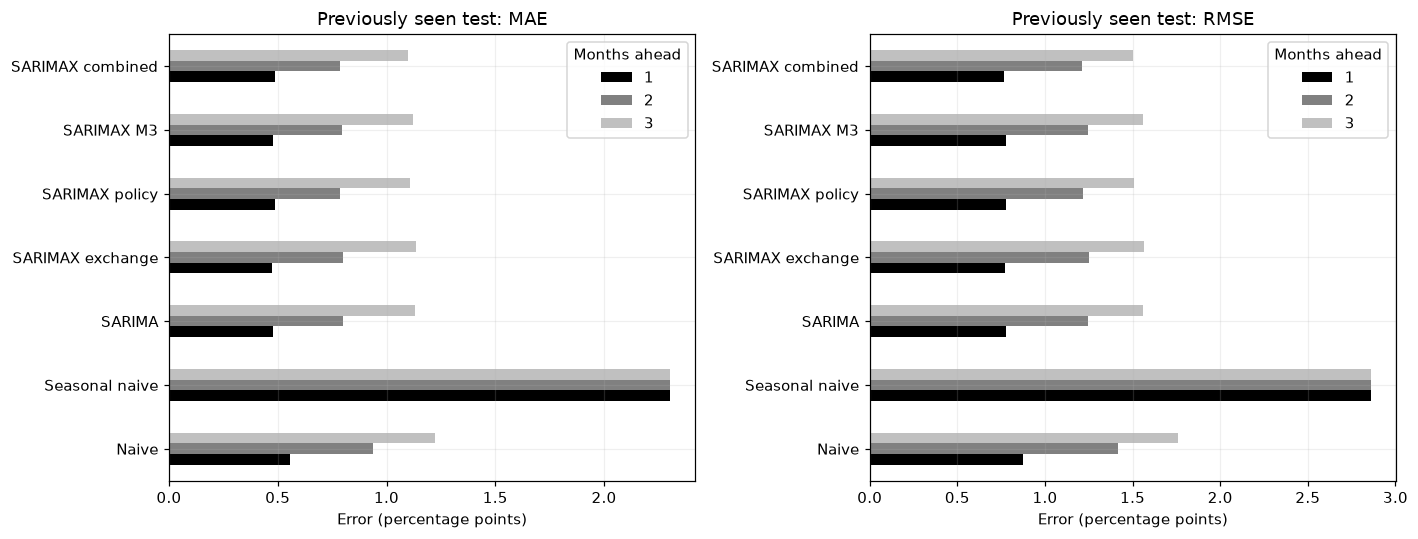

SARIMAX combined, 1 month(s): MAE 0.488 pp, RMSE 0.767 pp.
SARIMAX combined, 2 month(s): MAE 0.785 pp, RMSE 1.211 pp.
SARIMAX combined, 3 month(s): MAE 1.099 pp, RMSE 1.502 pp.


model,Naive,SARIMA,SARIMAX M3,SARIMAX combined,SARIMAX exchange,SARIMAX policy,Seasonal naive
horizon,,,,,,,
1,0.8727,0.7756,0.7762,0.7674,0.7720,0.7766,2.8603
2,1.4161,1.2462,1.2474,1.2114,1.2515,1.2161,2.8603
3,1.7600,1.5600,1.5590,1.5019,1.5674,1.5084,2.8603


A lower error is better. These are not percentage accuracy scores.


In [14]:
test_metrics = metrics[metrics["phase"] == "Test"]
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for axis, measure in zip(axes, ["MAE", "RMSE"]):
    table = test_metrics.pivot(index="model", columns="horizon", values=measure).reindex(models)
    table.plot.barh(ax=axis, color=["black", "gray", "silver"])
    axis.set_title("Previously seen test: " + measure)
    axis.set_xlabel("Error (percentage points)")
    axis.set_ylabel("")
    axis.legend(title="Months ahead")
fig.tight_layout()
fig.savefig(OUT / "02_model_comparison.png")
plt.show()
plt.close(fig)

selected_metrics = test_metrics[test_metrics["model"] == selected_model]
for row in selected_metrics.itertuples():
    print(f"{selected_model}, {row.horizon} month(s): MAE {row.MAE:.3f} pp, RMSE {row.RMSE:.3f} pp.")
comparison = test_metrics.pivot(index="horizon", columns="model", values="RMSE")
display(comparison.round(4))
print("A lower error is better. These are not percentage accuracy scores.")

### D3. Plot actual versus predicted inflation
Show the selected model at each horizon. The forecast for each target was made at an earlier origin. Look for large misses and delayed responses when inflation rises or falls quickly.

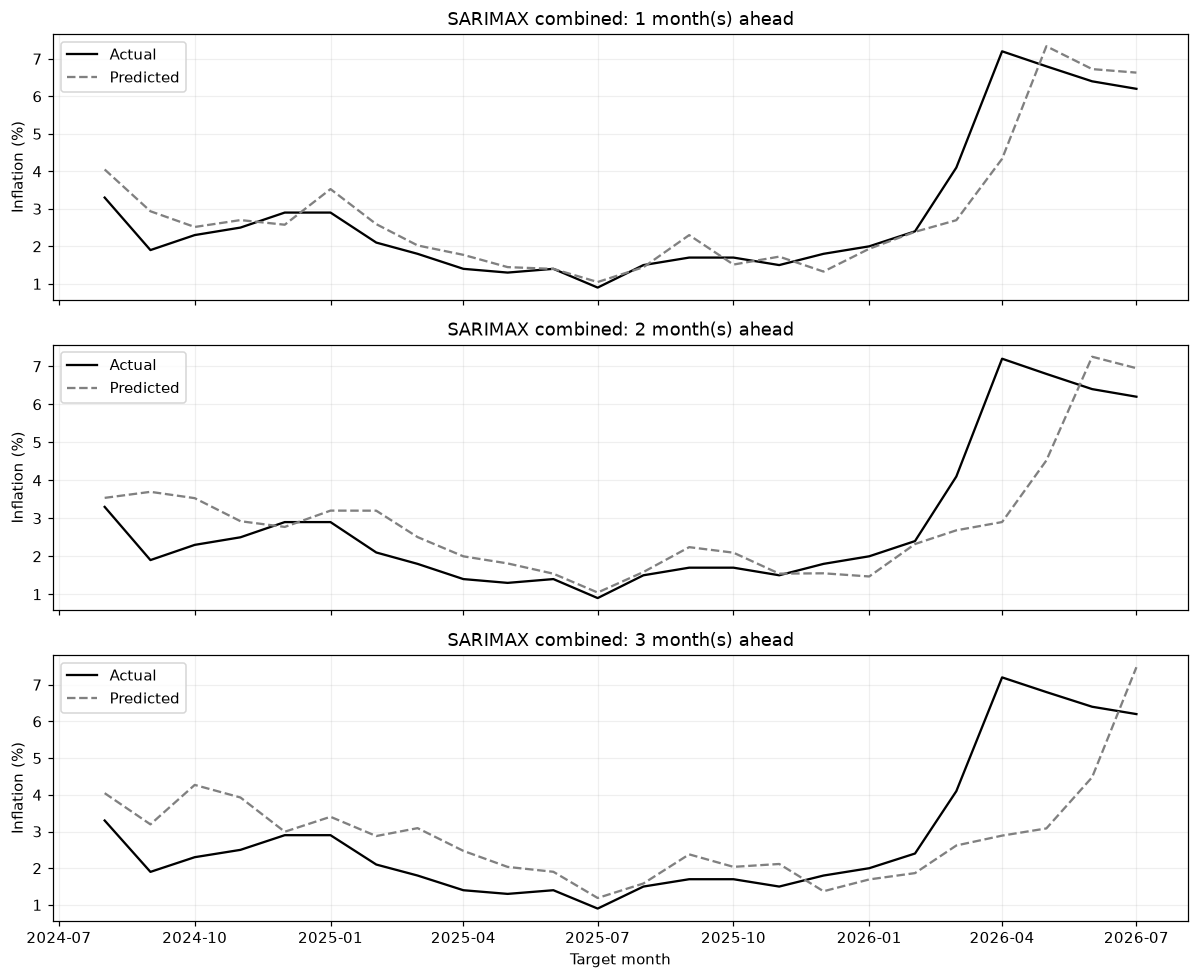

In [15]:
selected_results = results[(results["phase"] == "Test") & (results["model"] == selected_model)]
fig, axes = plt.subplots(3, 1, figsize=(11, 9), sharex=True)
for axis, horizon in zip(axes, [1, 2, 3]):
    rows = selected_results[selected_results["horizon"] == horizon].sort_values("target")
    axis.plot(rows["target"], rows["actual"], color="black", label="Actual")
    axis.plot(rows["target"], rows["predicted"], color="gray", linestyle="--", label="Predicted")
    axis.set_title(f"{selected_model}: {horizon} month(s) ahead")
    axis.set_ylabel("Inflation (%)")
    axis.legend()
axes[-1].set_xlabel("Target month")
fig.tight_layout()
fig.savefig(OUT / "03_actual_vs_predicted.png")
plt.show()
plt.close(fig)

### D4. Refit and forecast the next three months
Fit the validation-selected model through July 2026 and forecast August–October. Prepare future rows from known-earlier March–May indicators. Do not insert actual future economic values.

A basic residual check asks whether the fitted errors still have a pattern over time. If its p-value is below 0.05, keep the model provisional. Passing this one check would not prove the model is fully adequate.

In [16]:
origin = model_data.index[-1]
future_dates = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=3, freq="MS")
source_dates = future_dates - pd.DateOffset(months=5)
assert (source_dates <= origin - pd.DateOffset(months=2)).all()
future_x = pd.DataFrame(data.loc[source_dates, inputs].to_numpy(), index=future_dates, columns=lag_columns)
values, final_fit = make_forecast(selected_model, model_data, future_x)
forecast_table = pd.DataFrame({"target": future_dates, "forecast": values})
if final_fit is not None:
    assert final_fit.mle_retvals["converged"], "Final model did not converge"
    columns = models[selected_model]
    forecast_x = None
    if columns:
        forecast_x = (future_x[columns] - model_data[columns].mean()) / model_data[columns].std().replace(0, 1)
    prediction = final_fit.get_forecast(steps=3, exog=forecast_x)
    bounds = np.asarray(prediction.conf_int())
    forecast_table["lower_95"] = bounds[:, 0]
    forecast_table["upper_95"] = bounds[:, 1]
    residuals = final_fit.resid.iloc[max(24, int(final_fit.loglikelihood_burn)):]
    residual_check = acorr_ljungbox(residuals, lags=[12], model_df=2, return_df=True)
    display(residual_check.round(5))
    if residual_check["lb_pvalue"].iloc[0] < 0.05:
        print("Review needed: fitted errors still have a time pattern. Forecasts are provisional.")
    else:
        print("No remaining pattern detected at this check's lag; further review is still needed.")
else:
    print("Benchmark selected; fitted residual checks and intervals are not implemented for it.")
display(forecast_table.round(4))
forecast_table.to_csv(OUT / "forecast.csv", index=False)

,lb_stat,lb_pvalue
12,28.63746,0.00143


Review needed: fitted errors still have a time pattern. Forecasts are provisional.


C:\Users\Luzan\AppData\Local\Temp\ipykernel_24868\1336891348.py:27: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(forecast_table.round(4))


,target,forecast,lower_95,upper_95
0,2026-08-01,5.9444,5.0076,6.8812
1,2026-09-01,5.8117,4.5088,7.1146
2,2026-10-01,5.8300,4.2604,7.3996


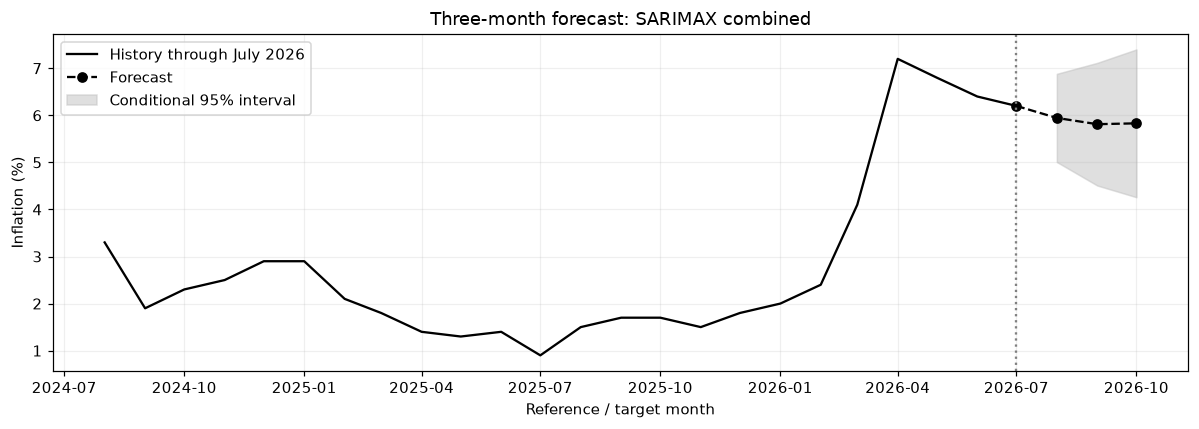

**Result:** SARIMAX combined has the lowest average validation RMSE among the complete, converged candidates. Compare its test errors with the benchmarks and SARIMA in the table above. A variable that helps in one period may not help in another. The intervals show model-based uncertainty, not guaranteed bounds. This is an academic forecast, not an official PSA or BSP forecast.

In [17]:
fig, axis = plt.subplots(figsize=(11, 4))
history = data["inflation"].iloc[-24:]
axis.plot(history.index, history, color="black", label="History through July 2026")
axis.plot([origin, *future_dates], [history.iloc[-1], *values], color="black",
          linestyle="--", marker="o", label="Forecast")
if "lower_95" in forecast_table:
    axis.fill_between(future_dates, forecast_table["lower_95"], forecast_table["upper_95"],
                      color="silver", alpha=0.5, label="Conditional 95% interval")
axis.axvline(origin, color="gray", linestyle=":")
axis.set_title("Three-month forecast: " + selected_model)
axis.set_ylabel("Inflation (%)")
axis.set_xlabel("Reference / target month")
axis.legend()
fig.tight_layout()
fig.savefig(OUT / "04_forecast.png")
plt.show()
plt.close(fig)

display(Markdown(f"**Result:** {selected_model} has the lowest average validation RMSE among the complete, converged candidates. "
    "Compare its test errors with the benchmarks and SARIMA in the table above. A variable that helps in one period may not help in another. "
    "The intervals show model-based uncertainty, not guaranteed bounds. This is an academic forecast, not an official PSA or BSP forecast."))

### D5. What this experiment covers
- Monthly national inflation, January 2010–July 2026.
- The proposal's three core indicators, tested individually and together.
- Naive and seasonal-naive comparisons, SARIMA and SARIMAX.
- Earlier-origin validation, a separate final block, and results at 1–3 months.
- MAE/RMSE, actual-versus-predicted plots, a basic error-pattern check and forecast intervals.

**Still limited:** source files have not been independently authenticated; original release dates/data versions are missing; policy text and definition changes need review; settings are a small fixed comparison, not a full study of predictor stability. The final period was previously seen. Unemployment is absent. No dashboard or usability assessment is included in this model-only experiment.

### D6. Plain-language result review
The combined SARIMAX was selected using validation errors only. Its reported final-test RMSE is **0.767, 1.211 and 1.502 percentage points** at 1, 2 and 3 months, compared with SARIMA **0.776, 1.246 and 1.560**. These differences are small; they do not prove that all three indicators always improve forecasts.

**Important:** the combined model did not converge at the August 2024 origin. This affects three of its 72 final-test forecasts. Its full test score includes those records and must be treated as provisional. The final July 2026 fit converged, but its residual check still found a time pattern. Keep both limitations when presenting the results.

Other test fits needing review:
- SARIMAX exchange: origin 2026-02-01.
- SARIMAX policy: origin 2025-05-01.
- SARIMAX combined: origin 2024-08-01.

No model was switched or retuned after seeing these test results. Earlier notebooks and application artifacts were not changed.